In [1]:
import pandas as pd

states_df = pd.read_csv('/content/Bachelors or Higher Degree for USA States.csv')
counties_df = pd.read_csv('/content/Bachelors or Higher Degree for States and Counties.csv')

print("States Dataset Columns:", states_df.columns.tolist())
display(states_df.head())

print("Counties Dataset Columns:", counties_df.columns.tolist())
display(counties_df.head())

States Dataset Columns: ['Unnamed: 0', ' Alabama', ' California', ' Arizona', ' Michigan', ' North Carolina', ' Minnesota', ' Arkansas', ' Montana', ' Georgia', ' Massachusetts', ' Florida', ' Kansas', ' Alaska', ' New York', ' Pennsylvania', ' Colorado', ' Wyoming', ' Wisconsin', ' Nevada', ' Texas', ' District of Columbia', ' Illinois', ' Maryland', ' Indiana', ' Connecticut', ' Missouri', ' Oklahoma', ' Tennessee', ' Iowa', ' Idaho', ' South Carolina', ' Louisiana', ' North Dakota', ' Vermont', ' New Mexico', ' West Virginia', ' Kentucky', ' Maine', ' Mississippi', ' New Jersey', ' Delaware', ' Hawaii', ' Nebraska', ' Utah', ' Ohio', ' Washington', ' South Dakota', ' Rhode Island', ' Oregon', ' Virginia', ' New Hampshire']


,Unnamed: 0,Alabama,California,Arizona,Michigan,North Carolina,Minnesota,Arkansas,Montana,Georgia,...,Hawaii,Nebraska,Utah,Ohio,Washington,South Dakota,Rhode Island,Oregon,Virginia,New Hampshire
0,2006-01-01,21.1,29.0,25.5,24.5,24.8,30.4,18.2,27.4,26.6,...,29.7,26.9,28.6,23.0,30.5,24.8,29.6,27.5,32.7,31.9
1,2007-01-01,21.4,29.5,25.3,24.7,25.6,31.0,19.3,27.0,27.1,...,29.2,27.5,28.7,24.1,30.3,25.0,29.8,28.3,33.6,32.5
2,2008-01-01,22.0,29.6,25.1,24.7,26.1,31.5,18.8,27.1,27.5,...,29.1,27.1,29.1,24.1,30.7,25.1,30.0,28.1,33.7,33.3
3,2009-01-01,22.0,29.9,25.6,24.6,26.5,31.5,18.9,27.4,27.5,...,29.6,27.4,28.5,24.1,31.0,25.1,30.5,29.2,34.0,32.0
4,2010-01-01,21.9,30.1,25.9,25.2,26.5,31.8,19.5,28.8,27.3,...,29.5,28.6,29.3,24.6,31.1,26.3,30.2,28.8,34.2,32.8


Counties Dataset Columns: ['Unnamed: 0', "Bachelor's Degree or Higher for Alabama", "Bachelor's Degree or Higher (5-year estimate) in Los Angeles County, CA", "Bachelor's Degree or Higher for California", "Bachelor's Degree or Higher (5-year estimate) in Harris County, TX", "Bachelor's Degree or Higher for Arizona", "Bachelor's Degree or Higher for Michigan", "Bachelor's Degree or Higher for North Carolina", "Bachelor's Degree or Higher for Minnesota", "Bachelor's Degree or Higher for Arkansas", "Bachelor's Degree or Higher (5-year estimate) in Lee County, FL", "Bachelor's Degree or Higher (5-year estimate) in Yuma County, AZ", "Bachelor's Degree or Higher (5-year estimate) in Yuba County, CA", "Bachelor's Degree or Higher (5-year estimate) in Lake County, CO", "Bachelor's Degree or Higher (5-year estimate) in Clay County, FL", "Bachelor's Degree or Higher (5-year estimate) in Gulf County, FL", "Bachelor's Degree or Higher (5-year estimate) in Clay County, GA", "Bachelor's Degree or Hi

,Unnamed: 0,Bachelor's Degree or Higher for Alabama,"Bachelor's Degree or Higher (5-year estimate) in Los Angeles County, CA",Bachelor's Degree or Higher for California,"Bachelor's Degree or Higher (5-year estimate) in Harris County, TX",Bachelor's Degree or Higher for Arizona,Bachelor's Degree or Higher for Michigan,Bachelor's Degree or Higher for North Carolina,Bachelor's Degree or Higher for Minnesota,Bachelor's Degree or Higher for Arkansas,...,"Bachelor's Degree or Higher (5-year estimate) in Hopkins County, KY","Bachelor's Degree or Higher (5-year estimate) in Caldwell County, KY","Bachelor's Degree or Higher (5-year estimate) in Campbell County, KY","Bachelor's Degree or Higher (5-year estimate) in Franklin County, KY","Bachelor's Degree or Higher (5-year estimate) in Gallatin County, KY","Bachelor's Degree or Higher (5-year estimate) in Lawrence County, KY","Bachelor's Degree or Higher (5-year estimate) in Breathitt County, KY","Bachelor's Degree or Higher (5-year estimate) in Christian County, KY","Bachelor's Degree or Higher (5-year estimate) in Crittenden County, KY","Bachelor's Degree or Higher (5-year estimate) in Cumberland County, KY"
0,2006-01-01,21.1,NaN,29.0,NaN,25.5,24.5,24.8,30.4,18.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007-01-01,21.4,NaN,29.5,NaN,25.3,24.7,25.6,31.0,19.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2008-01-01,22.0,NaN,29.6,NaN,25.1,24.7,26.1,31.5,18.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-01-01,22.0,NaN,29.9,NaN,25.6,24.6,26.5,31.5,18.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2010-01-01,21.9,29.0,30.1,27.7,25.9,25.2,26.5,31.8,19.5,...,13.2,14.0,26.3,27.2,9.0,8.2,10.4,13.7,9.3,7.9


In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Prepare the data
# Let's clean states_df columns (remove extra spaces)
states_df.columns = states_df.columns.str.strip()

# Set the 'Unnamed: 0' (Year) as index
matrix_df = states_df.set_index('Unnamed: 0')

# Handle missing values (if any) by filling with column mean
matrix_df = matrix_df.fillna(matrix_df.mean())

print("User-Item Matrix shape (Years as Users, States as Items):", matrix_df.shape)
print("Years:", list(matrix_df.index))
print("Sample States:", list(matrix_df.columns[:5]))

User-Item Matrix shape (Years as Users, States as Items): (16, 51)
Years: ['2006-01-01', '2007-01-01', '2008-01-01', '2009-01-01', '2010-01-01', '2011-01-01', '2012-01-01', '2013-01-01', '2014-01-01', '2015-01-01', '2016-01-01', '2017-01-01', '2018-01-01', '2019-01-01', '2020-01-01', '2021-01-01']
Sample States: ['Alabama', 'California', 'Arizona', 'Michigan', 'North Carolina']


In [3]:
def get_similarity_matrix(df, metric='cosine', axis=0):
    """
    Computes similarity matrix.
    axis=0: Compute similarity between rows (Users)
    axis=1: Compute similarity between columns (Items)
    """
    data = df.values if axis == 0 else df.T.values

    if metric == 'cosine':
        sim = cosine_similarity(data)
    elif metric == 'pearson':
        # pandas corr computes correlation column-wise
        if axis == 0:
            sim = df.T.corr(method='pearson').values
        else:
            sim = df.corr(method='pearson').values
    else:
        raise ValueError("Metric must be 'cosine' or 'pearson'")

    # Set diagonal elements to 0 to avoid self-similarity
    np.fill_diagonal(sim, 0)
    return sim

def user_based_collaborative_filter(df, metric='cosine', top_n=5):
    """
    User-based CF:
    Predict rating for User u and Item i:
    P(u, i) = mean(u) + sum( Sim(u, v) * (R(v, i) - mean(v)) ) / sum(|Sim(u, v)|)
    """
    # Row-wise mean (mean rating for each user/year)
    user_means = df.mean(axis=1).values.reshape(-1, 1)

    # Mean-centered ratings
    normalized_ratings = df.values - user_means

    # User-to-user similarity (axis=0)
    user_sim = get_similarity_matrix(df, metric=metric, axis=0)

    # Calculate predictions
    sim_sum = np.abs(user_sim).sum(axis=1, keepdims=True)
    # Prevent division by zero
    sim_sum = np.where(sim_sum == 0, 1, sim_sum)

    predicted_ratings_diff = np.dot(user_sim, normalized_ratings) / sim_sum
    predictions = user_means + predicted_ratings_diff

    return pd.DataFrame(predictions, index=df.index, columns=df.columns)

def item_based_collaborative_filter(df, metric='cosine'):
    """
    Item-based CF:
    Predict rating for User u and Item i:
    P(u, i) = sum( Sim(i, j) * R(u, j) ) / sum(|Sim(i, j)|)
    """
    # Item-to-item similarity (axis=1)
    item_sim = get_similarity_matrix(df, metric=metric, axis=1)

    # Weighted sum
    sim_sum = np.abs(item_sim).sum(axis=1)
    # Prevent division by zero
    sim_sum = np.where(sim_sum == 0, 1, sim_sum)

    predictions = np.dot(df.values, item_sim) / sim_sum

    return pd.DataFrame(predictions, index=df.index, columns=df.columns)

# Generate predictions using both techniques
user_pred_cos = user_based_collaborative_filter(matrix_df, metric='cosine')
item_pred_pearson = item_based_collaborative_filter(matrix_df, metric='pearson')

print("Predictions Ready.")

Predictions Ready.


In [4]:
def recommend_top_n(predictions_df, target_user, original_df, top_n=5, exclude_observed=False):
    """
    Recommends top-N items for a target user.
    """
    user_predictions = predictions_df.loc[target_user]

    if exclude_observed:
        # Mask out items that are already highly present / observed
        # Let's say we mask out items that have above-average original values
        threshold = original_df.loc[target_user].mean()
        observed_mask = original_df.loc[target_user] > threshold
        user_predictions = user_predictions.mask(observed_mask)

    recommendations = user_predictions.sort_values(ascending=False).head(top_n)
    return recommendations

# Example recommendation for target year '2021-01-01'
target_year = '2021-01-01' if '2021-01-01' in matrix_df.index else matrix_df.index[-1]

print(f"--- User-Based (Cosine) Recommendations for {target_year} ---")
print(recommend_top_n(user_pred_cos, target_year, matrix_df, top_n=5))

print(f"\n--- Item-Based (Pearson) Recommendations for {target_year} ---")
print(recommend_top_n(item_pred_pearson, target_year, matrix_df, top_n=5))

--- User-Based (Cosine) Recommendations for 2021-01-01 ---
District of Columbia    58.982721
Massachusetts           45.902316
Colorado                43.388996
Maryland                42.915573
Connecticut             42.362218
Name: 2021-01-01, dtype: float64

--- Item-Based (Pearson) Recommendations for 2021-01-01 ---
West Virginia    34.884559
Arkansas         34.869850
Mississippi      34.869044
Louisiana        34.839375
Kentucky         34.830472
Name: 2021-01-01, dtype: float64


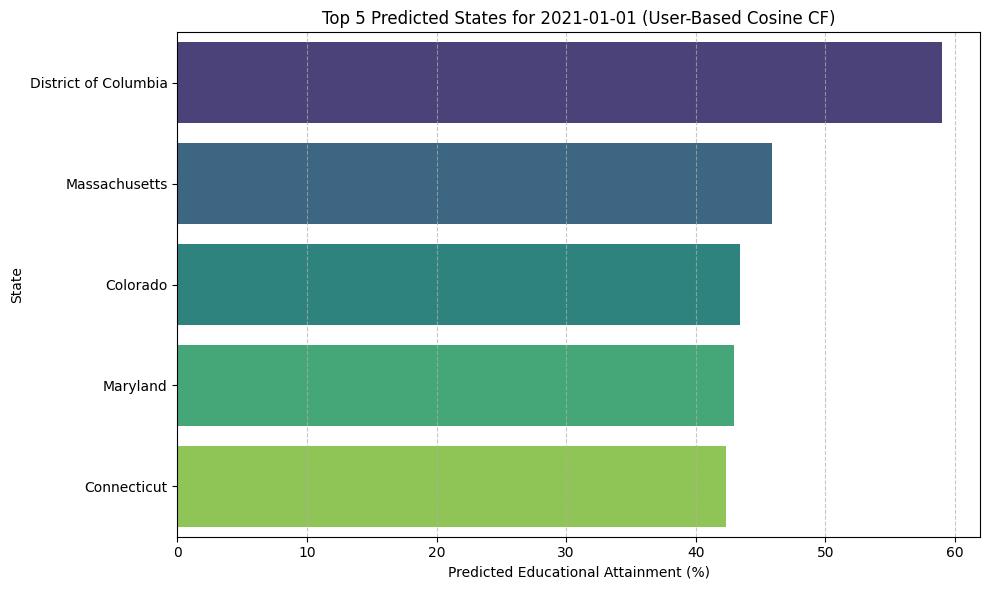

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get top 5 predicted states for the target year
top_5_predicted = recommend_top_n(user_pred_cos, target_year, matrix_df, top_n=5)

# Plot the data
plt.figure(figsize=(10, 6))
sns.barplot(x=top_5_predicted.values, y=top_5_predicted.index, palette='viridis', hue=top_5_predicted.index, legend=False)

plt.title(f'Top 5 Predicted States for {target_year} (User-Based Cosine CF)')
plt.xlabel('Predicted Educational Attainment (%)')
plt.ylabel('State')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

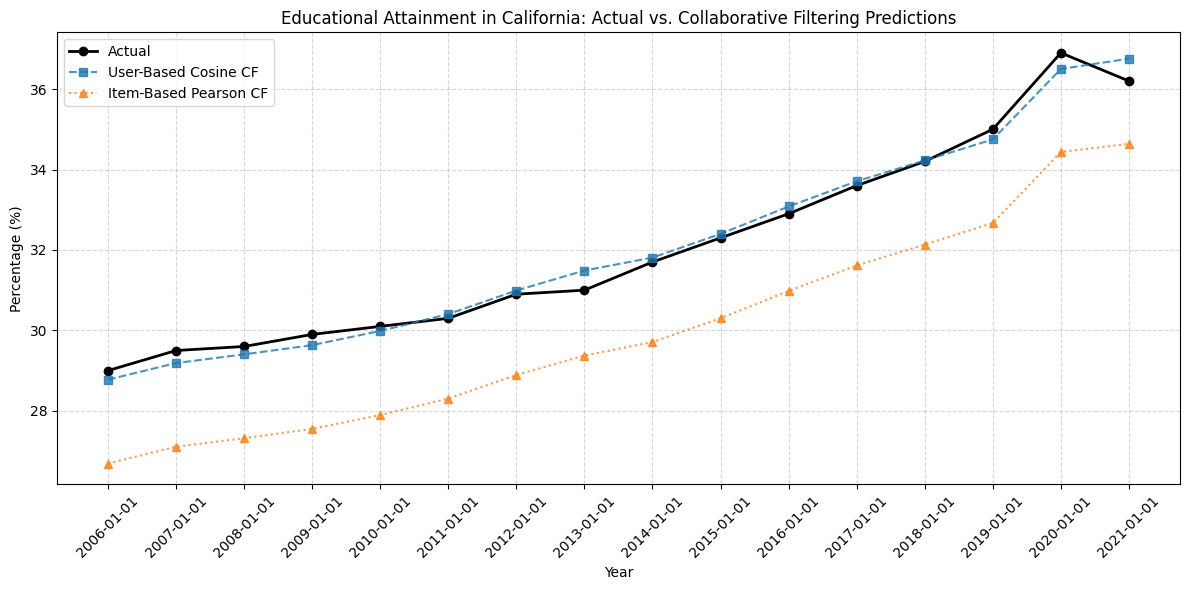

In [6]:
import matplotlib.pyplot as plt

# Select a state to compare
target_state = 'California'

# Extract historical values
actual_values = matrix_df[target_state]
user_predictions = user_pred_cos[target_state]
item_predictions = item_pred_pearson[target_state]

# Plot the comparison
plt.figure(figsize=(12, 6))
plt.plot(matrix_df.index, actual_values, marker='o', label='Actual', linewidth=2, color='black')
plt.plot(matrix_df.index, user_predictions, marker='s', linestyle='--', label='User-Based Cosine CF', alpha=0.8)
plt.plot(matrix_df.index, item_predictions, marker='^', linestyle=':', label='Item-Based Pearson CF', alpha=0.8)

plt.title(f'Educational Attainment in {target_state}: Actual vs. Collaborative Filtering Predictions')
plt.xlabel('Year')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

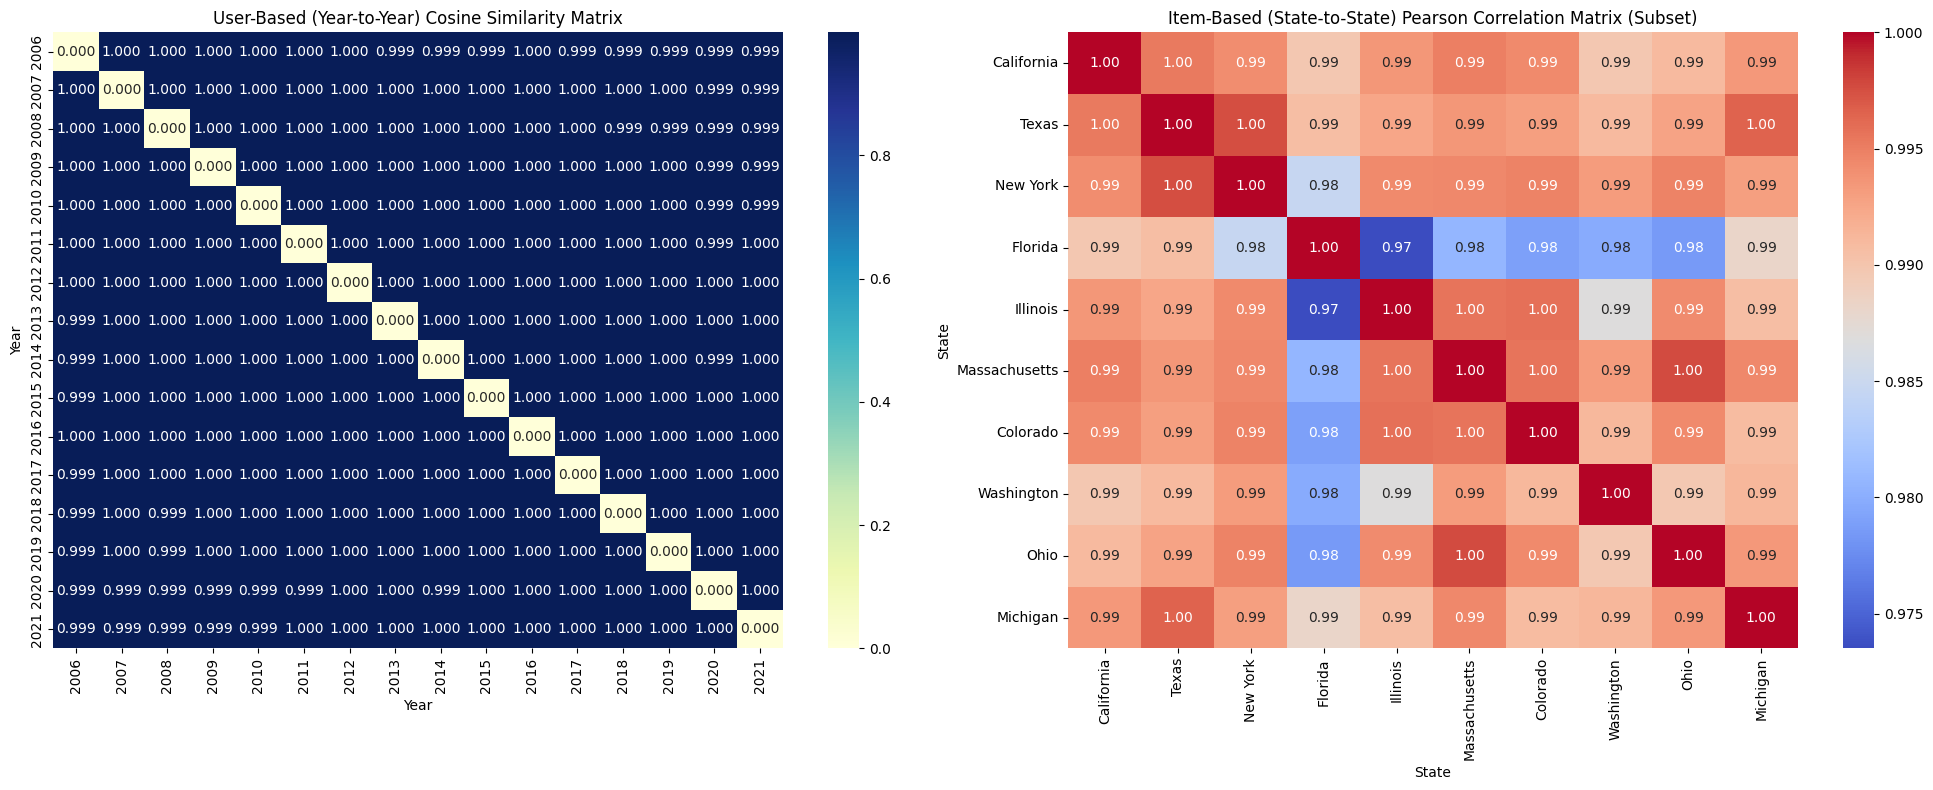

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate similarity matrices
# 1. User (Year-to-Year) Cosine Similarity Matrix
user_cosine_sim = get_similarity_matrix(matrix_df, metric='cosine', axis=0)

# 2. Item (State-to-State) Pearson Correlation Matrix
# We take a subset of states for better visual representation in a heatmap
sample_states = ['California', 'Texas', 'New York', 'Florida', 'Illinois', 'Massachusetts', 'Colorado', 'Washington', 'Ohio', 'Michigan']
state_subset_df = matrix_df[sample_states]
state_pearson_sim = state_subset_df.corr(method='pearson')

# Set up plotting grid
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot User Cosine Similarity
sns.heatmap(
    user_cosine_sim,
    annot=True,
    fmt=".3f",
    cmap='YlGnBu',
    xticklabels=matrix_df.index.str[:4],
    yticklabels=matrix_df.index.str[:4],
    ax=axes[0]
)
axes[0].set_title('User-Based (Year-to-Year) Cosine Similarity Matrix')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Year')

# Plot Item Pearson Correlation
sns.heatmap(
    state_pearson_sim,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    xticklabels=sample_states,
    yticklabels=sample_states,
    ax=axes[1]
)
axes[1].set_title('Item-Based (State-to-State) Pearson Correlation Matrix (Subset)')
axes[1].set_xlabel('State')
axes[1].set_ylabel('State')

plt.tight_layout()
plt.show()

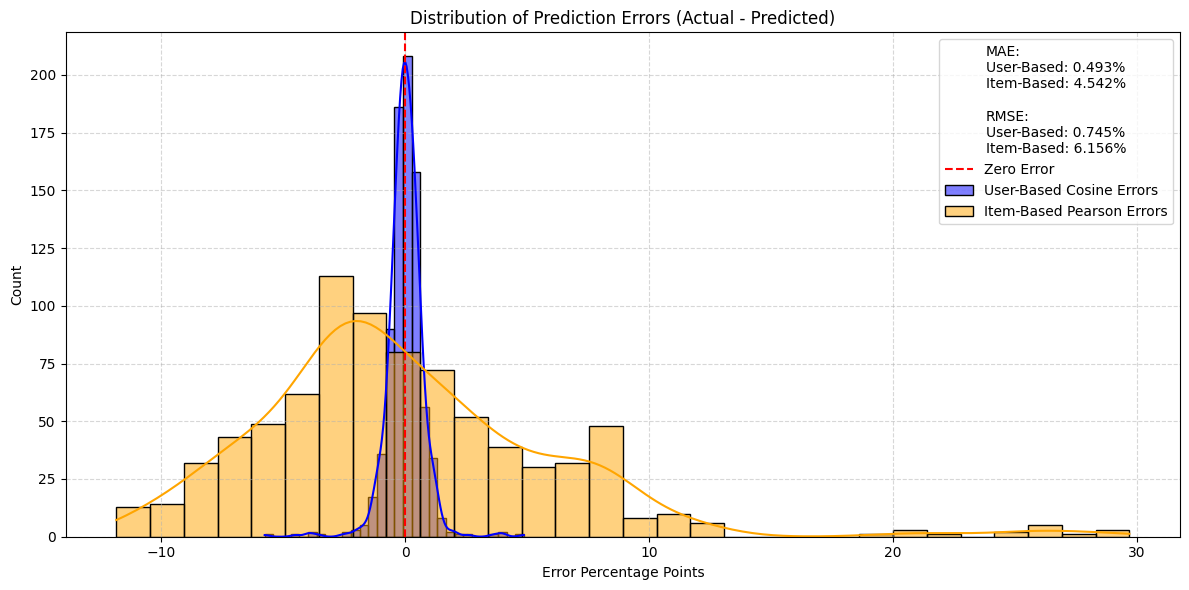

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate errors (residuals) across all states and years
# Flatten the dataframes to get all individual predictions
actuals_flat = matrix_df.values.flatten()
user_preds_flat = user_pred_cos.values.flatten()
item_preds_flat = item_pred_pearson.values.flatten()

user_errors = actuals_flat - user_preds_flat
item_errors = actuals_flat - item_preds_flat

# Plotting the distributions
plt.figure(figsize=(12, 6))
sns.histplot(user_errors, kde=True, label='User-Based Cosine Errors', color='blue', alpha=0.5, bins=30)
sns.histplot(item_errors, kde=True, label='Item-Based Pearson Errors', color='orange', alpha=0.5, bins=30)

plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')

# Calculate and print metrics
user_mae = np.mean(np.abs(user_errors))
item_mae = np.mean(np.abs(item_errors))
user_rmse = np.sqrt(np.mean(user_errors**2))
item_rmse = np.sqrt(np.mean(item_errors**2))

plt.title('Distribution of Prediction Errors (Actual - Predicted)')
plt.xlabel('Error Percentage Points')
plt.ylabel('Count')
plt.legend(title=f'MAE:\nUser-Based: {user_mae:.3f}%\nItem-Based: {item_mae:.3f}%\n\nRMSE:\nUser-Based: {user_rmse:.3f}%\nItem-Based: {item_rmse:.3f}%')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()